# 07 -- Full galaxy analysis, start to finish

**Goal:** this is the capstone notebook -- a complete, real analysis
combining every piece this notebook sequence has built and validated
separately:

1. An already-conditioned stellar template library (`04_template_calibration.ipynb`).
2. PA-aware dartboard spatial binning (`kinextract.binning`), matching
   a real, independently-verified reference binning scheme.
3. Sky-residual and emission-line masking (`05_noise_correlation.ipynb`).
4. Correlated-noise-aware whitening (`05_noise_correlation.ipynb`).
5. Parallel per-bin fitting *and* parallel Laplace uncertainty -- both
   genuinely necessary at this scale, not a demonstration toggle.
6. Real moment maps and radial kinematic profiles, built the way IFU
   kinematics papers actually build them.

Read this notebook as *the reason each earlier notebook exists*: every step
below is doing something a previous notebook motivated and tested in
isolation. If any step here is unclear, that earlier notebook is where the
explanation lives -- this one focuses on how they fit together.

**This is a genuinely large computation, not a quick demo.** Choose
`RMAX_ARCSEC` in Section 2 to cover as much of the field as you want
analyzed -- the default here (30\") is deliberately the *real* science
radius, not a coarsened stand-in, and matches the scale used in this
project's own real-data pPXF comparison (239 bins at this radius).
Per-bin fitting is parallelized (`fit_losvd_clean_parallel`); uncertainty
uses `laplace_losvd_uncertainty_parallel` (this package's primary
uncertainty engine -- see `02_realistic_mock_fit.ipynb` for why it
replaced bootstrap as the default: substantially better h4 coverage at a
fraction of bootstrap's per-bin cost, since it needs one closed-form
covariance per regularization-strength candidate rather than `n_boot`
full nonlinear refits). **Results are cached to disk** (Section 3) so
this only needs to run once per configuration -- change `RMAX_ARCSEC` or
any other binning/fit choice and it recomputes automatically; leave
everything the same and it loads instantly from the cache instead.

**A note on memory.** A real MUSE cube is several GB on disk, several
more once loaded (`load_muse_cube` converts to float64); Section 4 frees
the cube's own flux/error arrays explicitly (`cube.flux = None`) as soon
as every bin's own spectrum has been extracted, since they're not needed
again and the two parallel steps that follow need their own headroom.
`N_JOBS` (Section 3) is set explicitly here for a specific laptop's
measured core behavior -- the package's own default (`n_jobs=None`,
`multi_template.resolve_n_jobs`) is memory-aware instead: it estimates
available system memory and caps the worker count only if needed, so the
*same* notebook uses everything available on a large-memory machine (an
HPC node, say) without risking a crash on a small one. Set `N_JOBS = None`
(or your own explicit core count) if you're running this somewhere with
more memory to spare than this notebook's own default assumes.

In [1]:
import sys, os, time, pickle, warnings, gc
from pathlib import Path
SRC_DIR = "../../src"
sys.path.insert(0, SRC_DIR)

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, load_muse_cube, extract_aperture_spectrum, white_light_image,
    laplace_losvd_uncertainty_parallel, detect_emission_lines, gauss_hermite_model,
    fit_losvd_clean_parallel,
    DartboardBins, build_reflected_sin_theta_edges, assign_spaxels_to_bins,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset
from kinextract.noise_model import whiten

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

In [2]:
import matplotlib.patches as mpatches


def plot_bin_map(ax, bin_table, bins, values_by_bin_id, center_pix, pa_deg, pixel_scale,
                  background=None, cmap="RdBu_r", vmin=None, vmax=None,
                  grid_color="black", grid_lw=0.5, grid_alpha=0.6, colorbar_label=None,
                  add_cbar=True):
    """Paints each populated dartboard bin as a filled wedge at its real
    sky position/extent, with explicit grid-line boundaries drawn on top --
    replaces `imshow(paint_map(...))`: a discrete per-pixel raster plus a
    continuous colormap gives adjacent bins with similar values no visual
    separation at all, and bin edges only show up as raster jaggedness,
    not a real line. `background` (e.g. the white-light image), if given,
    is drawn underneath at reduced alpha for spatial context -- the same
    idea as overlaying kinematic maps on a galaxy image in a real paper
    figure.

    A bin whose value is NaN (a failed fit -- see `cleaning._failed_fit_result`)
    renders as plain grey (`set_bad`), not a color implying a real
    measurement -- consistent with `04_template_calibration.ipynb`'s own
    copy of this function.
    """
    bx, by = center_pix
    if background is not None:
        ax.imshow(background, origin="lower", cmap="gray", alpha=0.35, zorder=0)

    vals_present = np.array([v for v in values_by_bin_id.values() if np.isfinite(v)])
    if vmin is None:
        vmin = -np.nanmax(np.abs(vals_present)) if cmap == "RdBu_r" else np.nanmin(vals_present)
    if vmax is None:
        vmax = np.nanmax(np.abs(vals_present)) if cmap == "RdBu_r" else np.nanmax(vals_present)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)
    cmap_obj.set_bad("grey")

    for row in bin_table:
        bid = row["bin_id"]
        if bid not in values_by_bin_id:
            continue
        color = cmap_obj(norm(values_by_bin_id[bid]))
        if row["theta_mid"] is None:
            # collapsed center bin -- a full circle out to the first radial edge
            r_hi = bins.r_edges[1] / pixel_scale
            wedge = mpatches.Wedge((bx, by), r_hi, 0.0, 360.0, facecolor=color,
                                    edgecolor="none", zorder=1)
        else:
            r_lo = bins.r_edges[row["r_index"]] / pixel_scale
            r_hi = bins.r_edges[row["r_index"] + 1] / pixel_scale
            # local (PA-relative) angle -> sky angle, matching assign_spaxels_to_bins's
            # own rotation convention exactly (binning.py: sky = R(+pa) @ local)
            theta_lo = np.degrees(bins.theta_edges[row["theta_index"]]) + pa_deg
            theta_hi = np.degrees(bins.theta_edges[row["theta_index"] + 1]) + pa_deg
            wedge = mpatches.Wedge((bx, by), r_hi, theta_lo, theta_hi, width=r_hi - r_lo,
                                    facecolor=color, edgecolor="none", zorder=1)
        ax.add_patch(wedge)

    # grid lines drawn separately from the fill, so bin boundaries stay
    # crisp regardless of how similar two neighboring bins' colors are
    # r_edges[0] isn't a real bin boundary (the collapsed center bin's own
    # outer edge is r_edges[1] -- see the fill loop above), so skip it here
    # too, or it draws a small, meaningless circle inside the center bin
    t = np.linspace(0.0, 2 * np.pi, 400)
    for r_edge in bins.r_edges[1:]:
        rp = r_edge / pixel_scale
        ax.plot(bx + rp * np.cos(t), by + rp * np.sin(t), color=grid_color,
                lw=grid_lw, alpha=grid_alpha, zorder=2)
    # angular spokes start at the *center bin's own* outer edge (r_edges[1] --
    # matching the collapsed-center-bin fill above, not r_edges[0]/the true
    # center), so the innermost bin renders as a plain undivided circle
    # instead of looking cut into wedges
    if bins.n_angular > 1:
        r_inner_pix = bins.r_edges[1] / pixel_scale
        r_max_pix = bins.r_edges[-1] / pixel_scale
        for theta_edge in bins.theta_edges:
            th = theta_edge + np.radians(pa_deg)
            ax.plot([bx + r_inner_pix * np.cos(th), bx + r_max_pix * np.cos(th)],
                    [by + r_inner_pix * np.sin(th), by + r_max_pix * np.sin(th)],
                    color=grid_color, lw=grid_lw, alpha=grid_alpha, zorder=2)
        # kinematic major axis (local theta=0, the angular scheme's own narrowest-sector
        # direction -- see assign_spaxels_to_bins's own PA-rotation convention above) --
        # drawn as a full diameter through the center, not just one ray, so both the
        # receding and approaching sides are marked. White + dotted so it reads clearly
        # against both the dark grid lines and whatever colormap is in use.
        th_major = np.radians(pa_deg)
        ax.plot([bx - r_max_pix * np.cos(th_major), bx + r_max_pix * np.cos(th_major)],
                [by - r_max_pix * np.sin(th_major), by + r_max_pix * np.sin(th_major)],
                color="white", lw=1.5, ls=":", zorder=3)

    if add_cbar:
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.046)
        if colorbar_label:
            cbar.set_label(colorbar_label)
    ax.set_aspect("equal")

## 1. Load the cube and the already-conditioned template library

A real E-MILES grid has hundreds of age/metallicity combinations -- far more
free parameters than any one spectrum's own S/N can usefully constrain, and
degenerate template mixtures are a real, measured source of bias (see
`02_realistic_mock_fit.ipynb`). `04_template_calibration.ipynb` solves this
once, for the whole target, by iteratively fitting every dartboard bin
against the full grid and keeping only the templates whose NNLS weight
actually survives somewhere -- `ngc5102_template_subset.npz`'s
`union_selected`. This notebook reuses that output directly rather than
re-deriving it: conditioning is a per-target, do-it-once step, not something
a downstream analysis notebook should redo on every run.

cube: (3681, 317, 318) (n_wave, ny, nx), pixel_scale=0.20000000000000015"
loaded radial (V, sigma) profile: 14 radii (from 04_template_calibration.ipynb's own full-grid fit)
loaded 31 conditioned templates (of the full E-MILES grid):
  Ebi1.30Zm0.25T00.0800_iTp0.00_baseFe.fits  age=0.08 Gyr  [M/H]=-0.25
  Ebi1.30Zm0.35T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T06.5000_iTp0.00_baseFe.fits  age=6.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.0000_iTp0.00_baseFe.fits  age=7.00 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.5000_iTp0.00_baseFe.fits  age=7.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.66T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=-0.66
  Ebi1.30Zm0.66T00.0500_iTp0.00_baseFe.fits  age=0.05 Gyr  [M/H]=-0.66
  Ebi1.30Zm0.66T00.0600_iTp0.00_baseFe.fits  age=0.06 Gyr  [M/H]=-0.66
  Ebi1.30Zm1.49T00.5000_iTp0.00_baseFe.fits  age=0.50 Gyr  [M/H]=-1.49
  Ebi1.30Zm1.49T01.5000_iTp0.00_baseFe.fits  age=1.50 Gyr  [M/H]=-1.49
  Ebi1.30Zm1.49T02.2500_iTp0.00_baseFe.fits  age=2.25 Gy

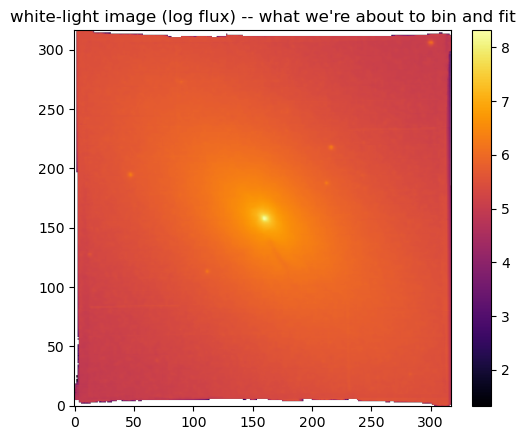

In [3]:
CUBE_PATH = "muse_download/ADP.2017-03-22T15:25:58.757.fits"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc5102_template_subset.npz"
RADIAL_KINEMATICS_PATH = "../data/muse/ngc5102_radial_kinematics.npz"
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
Z = 468.0 / 299792.458  # NGC 5102 systemic velocity ~468 km/s (NED)

if not os.path.exists(CUBE_PATH):
    raise FileNotFoundError(
        f"{CUBE_PATH} not found -- see 04_template_calibration.ipynb's DATA_MODE cell "
        "to download it (or point CUBE_PATH at any other MUSE Phase 3 cube)."
    )
if not os.path.exists(RADIAL_KINEMATICS_PATH):
    raise FileNotFoundError(
        f"{RADIAL_KINEMATICS_PATH} not found -- run 04_template_calibration.ipynb's Section 7/10 "
        "in DATA_MODE='download' first (it now saves this radial (V, sigma) profile alongside the "
        "template subset -- see Section 4's own note on why this notebook needs it)."
    )

cube = load_muse_cube(CUBE_PATH)
ny, nx = cube.shape
print(f"cube: {cube.flux.shape} (n_wave, ny, nx), pixel_scale={cube.pixel_scale}\"")

radial_kin = np.load(RADIAL_KINEMATICS_PATH)
print(f"loaded radial (V, sigma) profile: {len(radial_kin['r_mid'])} radii "
      f"(from 04_template_calibration.ipynb's own full-grid fit)")

subset = load_template_subset(TEMPLATE_SUBSET_PATH)
union_idx = subset["union_selected"]
select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} conditioned templates (of the full E-MILES grid):")
for n, a, m in zip(names, ages, metals):
    print(f"  {n}  age={a:.2f} Gyr  [M/H]={m:+.2f}")

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    white_light = white_light_image(cube)
fig, ax = plt.subplots(figsize=(5, 4.5))
with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)
im = ax.imshow(log_white_light, origin="lower", cmap="inferno")
ax.set_title("white-light image (log flux) -- what we're about to bin and fit")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

## 2. PA-aware dartboard binning -- choose your own `RMAX_ARCSEC`

A single spaxel's own S/N falls off fast away from the nucleus -- too low,
on its own, to usefully constrain a LOSVD shape (`05_noise_correlation.ipynb`'s
own low-S/N aperture, for example, cannot support h3/h4 at all). Spatial
binning trades resolution for S/N by combining many faint spaxels into one
spectrum per bin.

**Why PA-aware, specifically.** `kinextract.binning`'s own default
(`uniform_theta_edges`) bins equal in angle, with no assumed axis -- the
right choice when nothing about the target's orientation is known yet.
Here we *do* know NGC 5102's kinematic major axis, so this notebook uses
`build_reflected_sin_theta_edges` + `assign_spaxels_to_bins`'s `pa_deg`
parameter instead: sectors come out narrowest along the major axis (where
rotation actually shows up in the LOSVD) and widest along the minor axis
(where it doesn't) -- concentrating angular resolution exactly where it's
useful. `REFERENCE_R_EDGES_ARCSEC` and `N_THETA_PER_QUADRANT=5` below match
an independent reference binning scheme exactly (`bin_r.out`/
`bin_v.out`'s own edges; see `binning.py`'s module docstring for the
verification), rescaled to this cube's field of view and truncated at
whatever `RMAX_ARCSEC` you choose.

**`RMAX_ARCSEC` is the one parameter you're meant to change.** Larger
values cover more of the field at the cost of more bins (and therefore
more per-bin fitting/uncertainty wall-clock, the dominant cost -- see the
intro markdown above). The default (30\") is a real science radius on
this target, not a coarsened demo -- change it here, then re-run from
this cell down; a different value invalidates the cache automatically
(Section 3).

219 populated bins (17 radial x 20 angular) out to r=28.53" (requested RMAX_ARCSEC=29.66", snapped down to the nearest real bin edge -- no partial sliver ring)


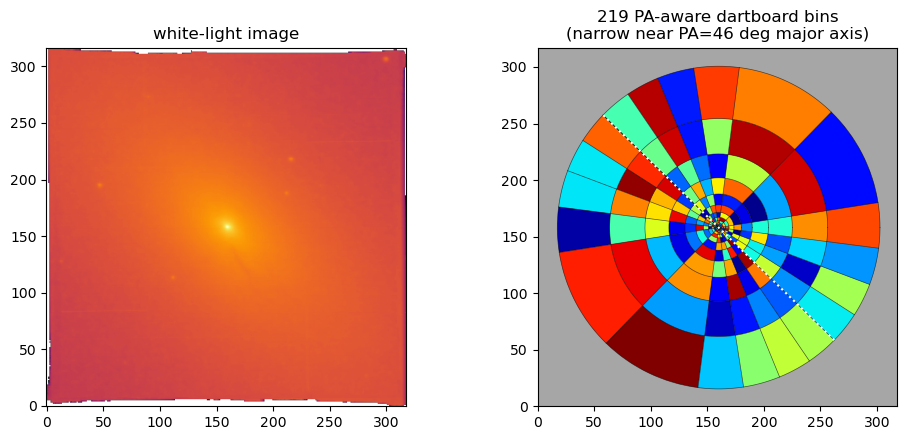

In [4]:
PA_DEG = 45.77 + 90.0       # NGC 5102's own kinematic major-axis PA
N_THETA_PER_QUADRANT = 5    # matches an independent reference bin_v.out exactly
REFERENCE_R_EDGES_ARCSEC = np.array([
    0.021, 0.048, 0.088, 0.147, 0.235, 0.365, 0.557, 0.841, 1.261, 1.883,
    2.801, 4.160, 6.171, 9.143, 13.540, 20.044, 29.662, 43.888,
])  # an independent reference dataset's own radial bin edges (bin_r.out's "rup" column) -- rescaled/truncated below

RMAX_ARCSEC = REFERENCE_R_EDGES_ARCSEC[-2]          # <-- the parameter to change; radial coverage in arcsec


with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    signal_map = np.nanmedian(cube.flux, axis=0)
    noise_map = np.nanmedian(cube.error, axis=0)
good0 = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)

by, bx = np.unravel_index(np.nanargmax(np.where(good0, signal_map, np.nan)), signal_map.shape)
x_arcsec = (np.arange(nx) - bx) * cube.pixel_scale
y_arcsec = (np.arange(ny) - by) * cube.pixel_scale
xx, yy = np.meshgrid(x_arcsec, y_arcsec)
r_arcsec = np.hypot(xx, yy)
good = good0 & (r_arcsec <= RMAX_ARCSEC)

# rescale the reference radial edges to this cube's own field of view, then truncate at RMAX_ARCSEC
fov_half_extent = 0.5 * min(nx, ny) * cube.pixel_scale
r_edges_full = REFERENCE_R_EDGES_ARCSEC * (0.9 * fov_half_extent / REFERENCE_R_EDGES_ARCSEC[-1])
# Snap DOWN to the nearest real (rescaled) reference edge <= RMAX_ARCSEC --
# never append RMAX_ARCSEC itself as a brand-new edge. The old version did
# that unconditionally whenever r_edges_full's last kept entry fell short of
# RMAX_ARCSEC, which is *every* time RMAX_ARCSEC isn't an exact rescaled
# edge value -- e.g. RMAX_ARCSEC = one of REFERENCE_R_EDGES_ARCSEC's own
# (unscaled) entries looks like it should land exactly on a real edge, but
# r_edges_full is REFERENCE_R_EDGES_ARCSEC*scale_factor, a *different* set
# of numbers -- so it silently created a partial sliver ring (observed
# directly: RMAX_ARCSEC=REFERENCE_R_EDGES_ARCSEC[-2] produced a final ring
# only ~1.1 arcsec wide, versus ~9 arcsec for the ring just inside it).
r_edges = r_edges_full[r_edges_full <= RMAX_ARCSEC]
if len(r_edges) < 2:
    r_edges = r_edges_full[:2]

theta_edges = build_reflected_sin_theta_edges(N_THETA_PER_QUADRANT)
bins = DartboardBins(r_edges=r_edges, theta_edges=theta_edges, center=(bx, by))
bin_id_map, bin_table = assign_spaxels_to_bins((ny, nx), bins, pixel_scale=cube.pixel_scale, pa_deg=PA_DEG)
bin_id_map[~good] = -1
bin_table = [row for row in bin_table if np.any(bin_id_map == row["bin_id"])]
bin_ids = [row["bin_id"] for row in bin_table]
n_bins = len(bin_table)

print(f"{n_bins} populated bins ({bins.n_radial} radial x {bins.n_angular} angular) "
      f"out to r={r_edges[-1]:.2f}\" (requested RMAX_ARCSEC={RMAX_ARCSEC:.2f}\", "
      f"snapped down to the nearest real bin edge -- no partial sliver ring)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)
axes[0].imshow(log_white_light, origin="lower", cmap="inferno")
axes[0].set_title("white-light image")
# random (not spatially-ordered) color per bin -- tab20 cycles through only 20
# colors, so with 239 bins many *adjacent* wedges land on the same or a
# similar swatch; a random permutation over a wide-gamut colormap instead
# makes neighboring bins land on unrelated colors almost always, which is
# the property that actually matters for "can I tell bins apart"
_bin_color_rng = np.random.default_rng(0)
_random_bin_value = {bid: v for bid, v in zip(bin_ids, _bin_color_rng.permutation(len(bin_ids)))}
plot_bin_map(axes[1], bin_table, bins, _random_bin_value, center_pix=bins.center,
             pa_deg=PA_DEG, pixel_scale=cube.pixel_scale, background=white_light,
             cmap="jet", vmin=0, vmax=len(bin_ids) - 1, add_cbar=False)
axes[1].set_xlim(0, nx); axes[1].set_ylim(0, ny)
axes[1].set_title(f"{n_bins} PA-aware dartboard bins\n(narrow near PA={PA_DEG-90:.0f} deg major axis)")
plt.tight_layout(); plt.show()

## 3. Caching -- this run only needs to happen once per configuration

Everything below (masking, fitting, Laplace uncertainty) is deterministic
given the binning geometry, template selection, `rho`, and uncertainty
settings -- so this cell fingerprints all of that into one `CACHE_TAG`
and, if a matching result already exists on disk, loads it instantly
instead of recomputing. Change `RMAX_ARCSEC` (or any other setting in
Section 2, or `MEASURED_RHO`/`N_SAMPLES` below) and the tag changes, so a
new configuration always recomputes rather than silently reusing a stale
result for a different question.

In [5]:
MEASURED_RHO = 0.88  # from 05_noise_correlation.ipynb -- re-measure for your own target
N_SAMPLES = 300  # laplace_losvd_uncertainty's own default posterior-predictive sample budget
LAPLACE_SEED = 0
N_JOBS = 4  # measured faster than n_jobs=None (os.cpu_count()) on this machine's
            # performance/efficiency core mix -- see fit_losvd_parallel's own docstring.
            # An explicit value like this always overrides the package's own memory-aware
            # default (multi_template.resolve_n_jobs) -- on a large-memory machine (e.g. an
            # HPC node), set N_JOBS = None (or your own core count) instead, to use everything
            # available rather than this laptop-specific choice.
CLIP_SIGMA = 3.0     # fit_losvd_clean's clip threshold (in robust-scaled units -- see Section 4)
MAX_ITER = 3         # fit_losvd_clean's max refit iterations
ROBUST_SCALE = True  # see Section 4 markdown for why this matters on real data

CACHE_TAG = (f"rmax{RMAX_ARCSEC:.1f}_pa{PA_DEG:.1f}_nt{N_THETA_PER_QUADRANT}_nb{n_bins}_rho{MEASURED_RHO:.2f}"
             f"_laplace_nsamp{N_SAMPLES}_seed{LAPLACE_SEED}_clip{CLIP_SIGMA:.1f}_iter{MAX_ITER}_robust{ROBUST_SCALE}")
CACHE_PATH = CACHE_DIR / f"full_galaxy_{CACHE_TAG}.pkl"
print(f"cache key: {CACHE_TAG}")
print(f"cache path: {CACHE_PATH}  (exists: {CACHE_PATH.exists()})")

cache key: rmax29.7_pa135.8_nt5_nb219_rho0.88_laplace_nsamp300_seed0_clip3.0_iter3_robustTrue
cache path: cache/full_galaxy_rmax29.7_pa135.8_nt5_nb219_rho0.88_laplace_nsamp300_seed0_clip3.0_iter3_robustTrue.pkl  (exists: True)


## 4. Per-bin masking, fitting, and Laplace uncertainty

Three things happen per bin:

- **Sky-residual and emission-line masking** (`05_noise_correlation.ipynb`,
  `cleaning.detect_emission_lines`): OH-airglow residual windows are a
  fixed, known-bad wavelength list; emission contamination is data-driven
  -- whether a candidate line is actually in emission depends on the
  spectrum, so it's re-checked per bin rather than masked unconditionally.
- **Iterative sigma-clipping, robust-scaled, as the default cleaning step**
  (`fit_losvd_clean_parallel(..., robust_scale=True)`). The default
  (non-robust) clip threshold is measured against the *input* noise
  vector, assuming it's correctly calibrated (chi2_red ~ 1); real chi2_red
  on this target runs 11-28 (`05_noise_correlation.ipynb`), so a nominal
  "3 sigma" cut is actually under 1 *true* sigma almost everywhere, not
  just at genuine contamination -- clipping 90%+ of pixels in real bins
  and collapsing to a biased, unconstrained baseline if left on the
  default. `robust_scale=True` instead measures `CLIP_SIGMA` against a
  MAD-based robust estimate of the *current* residual's own scale
  (recomputed each iteration from the surviving pixels): realistic clip
  fractions, no runaway, and a cleaned fit that actually tracks the data's
  real continuum shape between contaminated regions instead of collapsing
  flat.

  **This still needs real per-target tuning, not a fire-and-forget
  default** -- `CLIP_SIGMA`/`MAX_ITER` above are a starting point, not a
  validated universal choice: too aggressive a `CLIP_SIGMA` risks clipping
  into real absorption features (the CaII triplet in particular, if a
  contaminating line sits close to one), and this method has no way to
  distinguish a genuine narrow contaminant from a region where the
  *continuum shape itself* is wrong (e.g. an imperfect sky subtraction
  that biases the local continuum level rather than adding a narrow
  spike) -- that failure mode isn't fixed by any per-pixel clipping
  threshold. Checked directly on this same target: clipped pixels
  concentrate at the *edges* of the fit window, not on the CaII triplet
  itself -- consistent with an edge-of-window model-data mismatch rather
  than line-specific contamination.
- **Grid centering from a cached radial profile, then fitting in
  parallel** (`fit_losvd_clean_parallel`): each bin's velocity grid is
  centered at `V +- 7*sigma` using its own radius's cached `(V, sigma)`
  from `04_template_calibration.ipynb`'s own full-grid fit (Section 1),
  not an independent per-bin wide-pass fit. Checked directly against a
  real run of this notebook: at fixed radius, `V` varies by at most
  ~30 km/s across angle and `sigma` by ~5-16 km/s -- both tiny next to
  the `7*sigma` margin (175-340 km/s here), so a per-radius estimate
  safely brackets every individual bin's own true `V`/`sigma`. This
  replaced an earlier per-bin wide-pass fit that measurably dominated
  this notebook's own "cheap" prep phase (793s of a 41.6-minute total
  run, for work that was only ever meant to pick a grid center). Once
  centered, the real fit -- `FitConfig`'s actual choices (regularization,
  `rho`, ...) and cleaning -- runs across *all* bins at once, parallelized
  the same way `fit_losvd_parallel` is.
- **Laplace uncertainty, in parallel** (`laplace_losvd_uncertainty_parallel`,
  this package's primary uncertainty engine -- see
  `02_realistic_mock_fit.ipynb` for the coverage-sweep evidence behind
  that default), on the *cleaned* pixel set each bin's own fit actually
  converged on -- not the original full set, so the Laplace covariance is
  computed at the same design matrix the point estimate itself used, not
  one that still includes pixels the fit excluded as contaminated.
  Continuum-cofitting is not used in this notebook, so `laplace_losvd_
  uncertainty`'s own "no continuum support yet" scope limit (see its
  module docstring) doesn't apply here.

**A note on warnings.** `select_lambda_aic_local` (inside every fit and
Laplace covariance evaluation below) checks every candidate `lam` in its
own scan grid, not just the one finally selected -- for some bins, a
rejected high-`lam` candidate trips `FitConfig`'s "knot spacing much finer
than `knot_spacing_kms` is calibrated against" warning even though that
candidate never gets used. Real diagnostic, over-eager trigger (fires
per-candidate, not per-selection) -- deduplicated to at most once per
worker process rather than raw hundreds of prints (see
`multi_template._limit_worker_threads`'s own docstring).

In [6]:
if CACHE_PATH.exists():
    print(f"loading cached result from {CACHE_PATH} ...")
    with open(CACHE_PATH, "rb") as f:
        bin_data = pickle.load(f)
    print(f"loaded {len(bin_data)} bins from cache -- skipping the fit/uncertainty below entirely")
    # cube.flux/cube.error (a real MUSE cube is several GB) are never needed again once
    # bin_data is loaded from cache -- free them now rather than waiting for the notebook
    # to end, same reasoning as the cache-miss branch below.
    cube.flux = None
    cube.error = None
    gc.collect()
else:
    WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0
    SKY_RESIDUAL_WINDOWS = [
        (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
    ]
    NSIG = 7
    # deduplicated, not silenced -- see Section 4's own note on why this fires
    # per rejected lam-candidate, not per bin
    warnings.filterwarnings("once", message=r".*much finer than.*knot_spacing_kms.*")

    t_start = time.time()
    bin_data = {}
    A_stack_w_list, y_w_list, cfg_list = [], [], []

    print(f"preparing {n_bins} bins (serial, cheap -- grid centers come from the cached "
          f"radial profile, not a per-bin wide-pass fit)...")
    for row in bin_table:
        bin_id = row["bin_id"]
        spaxel_mask = bin_id_map == bin_id
        wave_obs, flux_obs, error_obs = extract_aperture_spectrum(cube, spaxel_mask)
        wave_rest = wave_obs / (1.0 + Z)
        in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
        wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

        emission_windows = detect_emission_lines(wave_w, flux_w, error_w)
        all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
        wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=all_windows)
        _, errors = mask_wavelength_windows(wave_w, error_w, windows=all_windows)

        # nearest-radius lookup against 04_template_calibration.ipynb's own cached (V, sigma)
        # profile -- see Section 4's own note for why this is a safe stand-in for an
        # independent per-bin wide-pass fit here.
        r_idx = int(np.argmin(np.abs(radial_kin["r_mid"] - row["r_mid"])))
        v0, sigma0 = float(radial_kin["vherm"][r_idx]), float(radial_kin["sherm"][r_idx])

        cfg = FitConfig(vmin=v0 - NSIG * sigma0, vmax=v0 + NSIG * sigma0, rho=MEASURED_RHO)
        v_grid = cfg.build_velocity_grid()
        A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
        A_stack_w, y_w, L = whiten(A_stack, flux_fit, errors, rho=cfg.rho)

        A_stack_w_list.append(A_stack_w); y_w_list.append(y_w); cfg_list.append(cfg)
        bin_data[bin_id] = dict(wave_fit=wave_fit, flux_fit=flux_fit, errors=errors,
                                 n_spaxels=int(spaxel_mask.sum()),
                                 n_emission_windows=len(emission_windows),
                                 v_grid=v_grid, L=L,
                                 r_mid=row["r_mid"], theta_mid=row["theta_mid"])
    t_wide = time.time() - t_start
    n_with_emission = sum(1 for b in bin_data.values() if b["n_emission_windows"] > 0)
    print(f"  done in {t_wide:.0f}s ({n_with_emission} bins with detected emission)")

    # cube.flux/cube.error (a real MUSE cube is several GB as float64) are not needed
    # again -- every bin's own spectrum is already captured in bin_data/A_stack_w_list.
    # Free them explicitly *before* the two parallel steps below, which each need their
    # own headroom (n_jobs worker processes, each holding a per-bin design matrix) --
    # see this notebook's intro markdown and multi_template.resolve_n_jobs's own
    # docstring for the memory-safety reasoning (this is what let a real 16GB machine
    # run this notebook without exhausting memory).
    cube.flux = None
    cube.error = None
    gc.collect()

    print(f"fitting {n_bins} bins in parallel with cleaning (n_jobs={N_JOBS}, "
          f"clip_sigma={CLIP_SIGMA}, robust_scale={ROBUST_SCALE})...")
    t0 = time.time()
    results = fit_losvd_clean_parallel(A_stack_w_list, y_w_list, cfg_list, clip_sigma=CLIP_SIGMA,
                                        max_iter=MAX_ITER, robust_scale=ROBUST_SCALE, n_jobs=N_JOBS)
    t_fit = time.time() - t0
    print(f"  done in {t_fit:.0f}s ({t_fit/n_bins:.1f}s/bin)")

    for bin_id, result, A_stack_w in zip(bin_ids, results, A_stack_w_list):
        bd = bin_data[bin_id]
        bd["result"] = result
        bd["moments"] = compute_losvd_moments(bd["v_grid"], result["b"], fit_h3h4=True)
        bd["clipped_mask"] = result["clipped_mask"]
        bd["n_clipped"] = result["n_clipped"]
        # full-pixel model for plotting -- w/b are global, so apply them to every
        # pixel (including clipped ones), not just the surviving subset, so later
        # sections can show the whole spectrum with clipped points marked
        A_eff_full = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
        bd["model"] = bd["L"] @ (A_eff_full @ result["b"])

    n_clipped_total = sum(bd["n_clipped"] for bd in bin_data.values())
    n_pix_total = sum(len(bd["errors"]) for bd in bin_data.values())
    per_bin_frac = [bd["n_clipped"] / len(bd["errors"]) for bd in bin_data.values()]
    print(f"  cleaning clipped {n_clipped_total}/{n_pix_total} pixels overall "
          f"({100*n_clipped_total/n_pix_total:.1f}%), median {np.median(per_bin_frac):.1%} per bin, "
          f"max {np.max(per_bin_frac):.1%} per bin")

    print(f"computing Laplace uncertainty for {n_bins} bins in parallel "
          f"(n_jobs={N_JOBS}, n_samples={N_SAMPLES})...")
    t0 = time.time()
    # Laplace covariance on each bin's own *cleaned* pixel set (matching what its
    # point estimate actually converged on), not the original full one -- keeps the
    # Hessian evaluated at the same design matrix the point estimate itself used.
    A_stack_w_clean_list = [A_stack_w_list[i][:, ~bin_data[bid]["clipped_mask"], :]
                             for i, bid in enumerate(bin_ids)]
    y_w_clean_list = [y_w_list[i][~bin_data[bid]["clipped_mask"]] for i, bid in enumerate(bin_ids)]
    laps = laplace_losvd_uncertainty_parallel(A_stack_w_clean_list, y_w_clean_list, cfg_list,
                                               n_samples=N_SAMPLES, seed=LAPLACE_SEED, n_jobs=N_JOBS)
    t_lap = time.time() - t0
    print(f"  done in {t_lap:.0f}s ({t_lap/n_bins:.1f}s/bin)")

    for bin_id, lap in zip(bin_ids, laps):
        bd = bin_data[bin_id]
        bd["sherm_std"] = lap["sherm_std"]
        bd["vherm_std"] = lap["vherm_std"]
        bd["h3_std"] = lap["h3_std"]
        bd["h4_std"] = lap["h4_std"]
        # The reported LOSVD is the Laplace posterior-predictive median/band, not the
        # point estimate -- the band is centered on b_median, not on bd["result"]["b"],
        # so presenting the point estimate next to a band that isn't centered on it is
        # misleading (see uncertainty.bootstrap_losvd's own b_median docstring for the
        # same reasoning, which applies identically here).
        bd["b_median"] = lap["b_median"]
        bd["b_p16"] = lap["b_p16"]
        bd["b_p84"] = lap["b_p84"]

    t_total = time.time() - t_start
    print(f"total: {t_total/60:.1f} min for {n_bins} bins")

    with open(CACHE_PATH, "wb") as f:
        pickle.dump(bin_data, f)
    print(f"cached to {CACHE_PATH}")

loading cached result from cache/full_galaxy_rmax29.7_pa135.8_nt5_nb219_rho0.88_laplace_nsamp300_seed0_clip3.0_iter3_robustTrue.pkl ...
loaded 219 bins from cache -- skipping the fit/uncertainty below entirely


## 5. A few example bins, before trusting the aggregate

Same discipline this project's own head-to-head pPXF comparison uses:
look at individual spectral fits and their extracted LOSVDs directly,
not just the summary numbers, before trusting a map or profile built from
all of them.

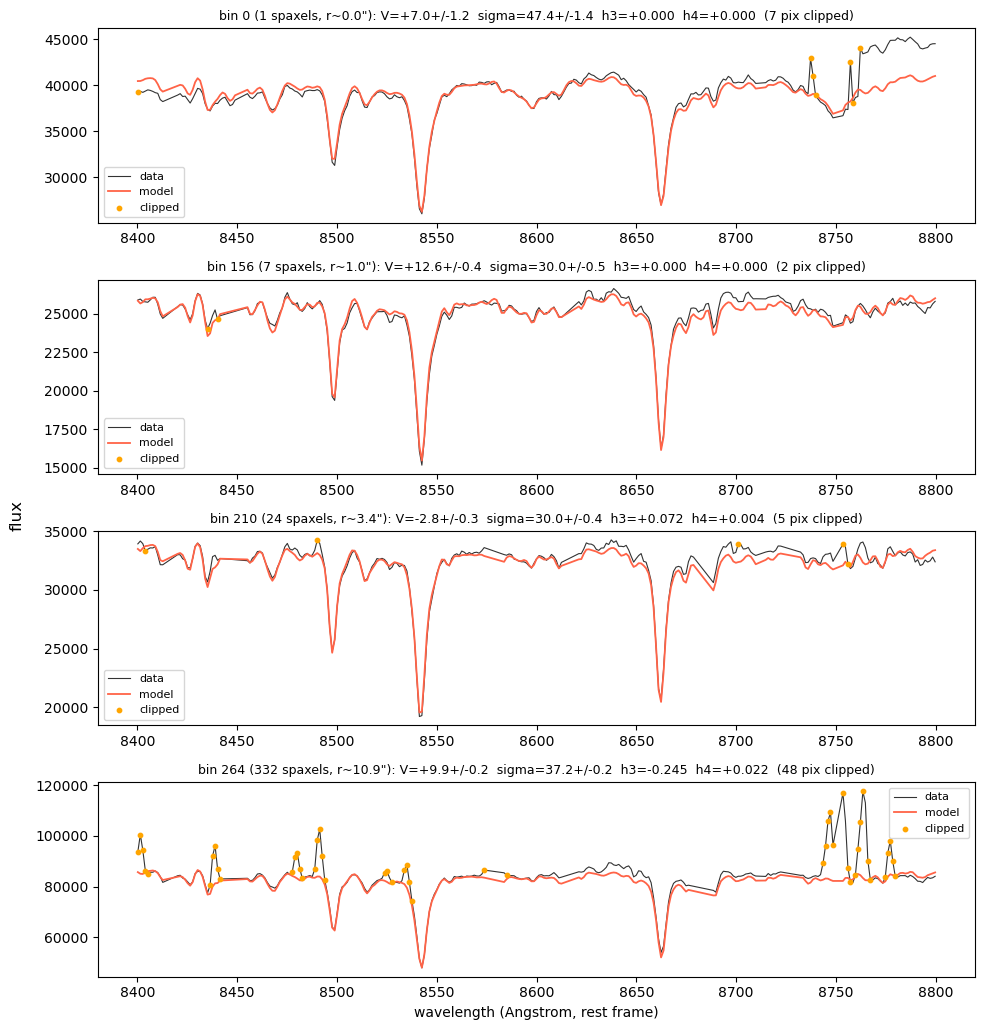

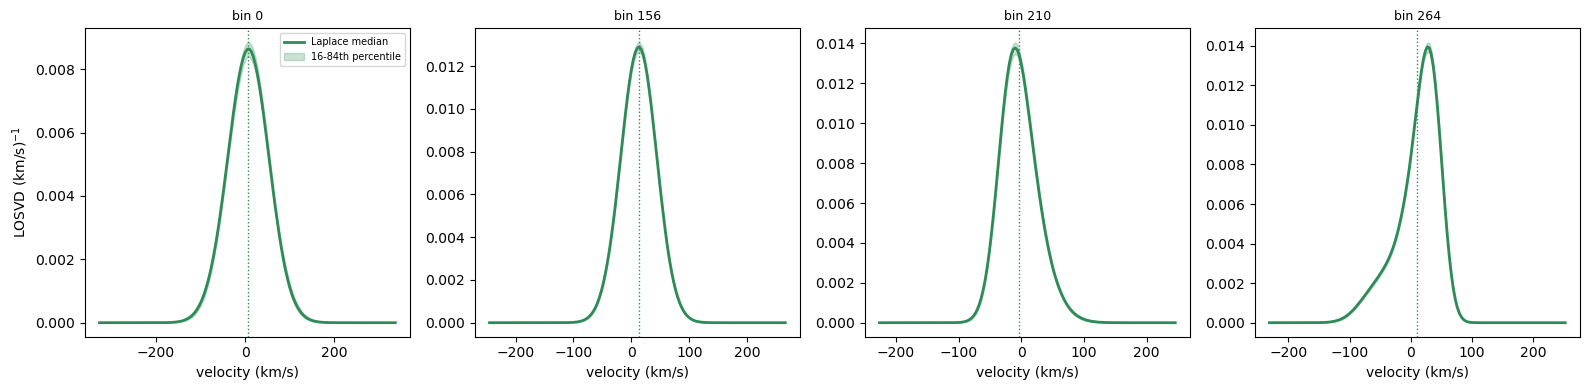

In [7]:
example_ids = sorted(bin_ids)[:: max(1, len(bin_ids) // 4)][:4]

fig, axes = plt.subplots(len(example_ids), 1, figsize=(10, 2.6 * len(example_ids)), sharex=False)
axes = np.atleast_1d(axes)
for ax, bid in zip(axes, example_ids):
    bd = bin_data[bid]
    ax.plot(bd["wave_fit"], bd["flux_fit"], color="black", lw=0.8, alpha=0.8, label="data")
    ax.plot(bd["wave_fit"], bd["model"], color="tomato", lw=1.3, label="model")
    clipped = bd["clipped_mask"]
    if np.any(clipped):
        ax.scatter(bd["wave_fit"][clipped], bd["flux_fit"][clipped], color="orange", s=10,
                   zorder=5, label="clipped")
    m = bd["moments"]
    ax.set_title(f"bin {bid} ({bd['n_spaxels']} spaxels, r~{bd['r_mid']:.1f}\"): "
                 f"V={m['vherm']:+.1f}+/-{bd['vherm_std']:.1f}  sigma={m['sherm']:.1f}+/-{bd['sherm_std']:.1f}  "
                 f"h3={m['h3']:+.3f}  h4={m['h4']:+.3f}  ({bd['n_clipped']} pix clipped)",
                 fontsize=9)
    ax.legend(fontsize=8)
axes[-1].set_xlabel("wavelength (Angstrom, rest frame)")
fig.supylabel("flux")
plt.tight_layout(); plt.show()

# The reported LOSVD is the Laplace posterior-predictive median (b_median), with its
# 16th/84th-percentile band -- not bd["result"]["b"]'s own point estimate, which the
# band is not centered on (see the storage loop above's own comment on why).
fig, axes = plt.subplots(1, len(example_ids), figsize=(4.0 * len(example_ids), 4), sharey=False)
axes = np.atleast_1d(axes)
for ax, bid in zip(axes, example_ids):
    bd = bin_data[bid]
    v_grid = bd["v_grid"]
    ax.plot(v_grid, bd["b_median"], color="seagreen", lw=2.0, label="Laplace median")
    ax.fill_between(v_grid, bd["b_p16"], bd["b_p84"], color="seagreen", alpha=0.25,
                     label="16-84th percentile")
    ax.axvline(bd["moments"]["vherm"], color="seagreen", ls=":", lw=1.0)
    ax.set_title(f"bin {bid}", fontsize=9)
    ax.set_xlabel("velocity (km/s)")
axes[0].set_ylabel(r"LOSVD (km/s)$^{-1}$")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Moment maps

**This is the point of doing spatial binning in the first place**, and it's
worth building properly. Every bin's spectrum represents *every spaxel that
went into it equally* -- so the right way to visualize a per-bin result
spatially is to paint each spaxel in the original image with its own bin's
value (`plot_bin_map` above), then `imshow` the result. This fills the
galaxy's actual footprint with color, the way a real IFU kinematics map
looks -- not a handful of dots at bin centers.

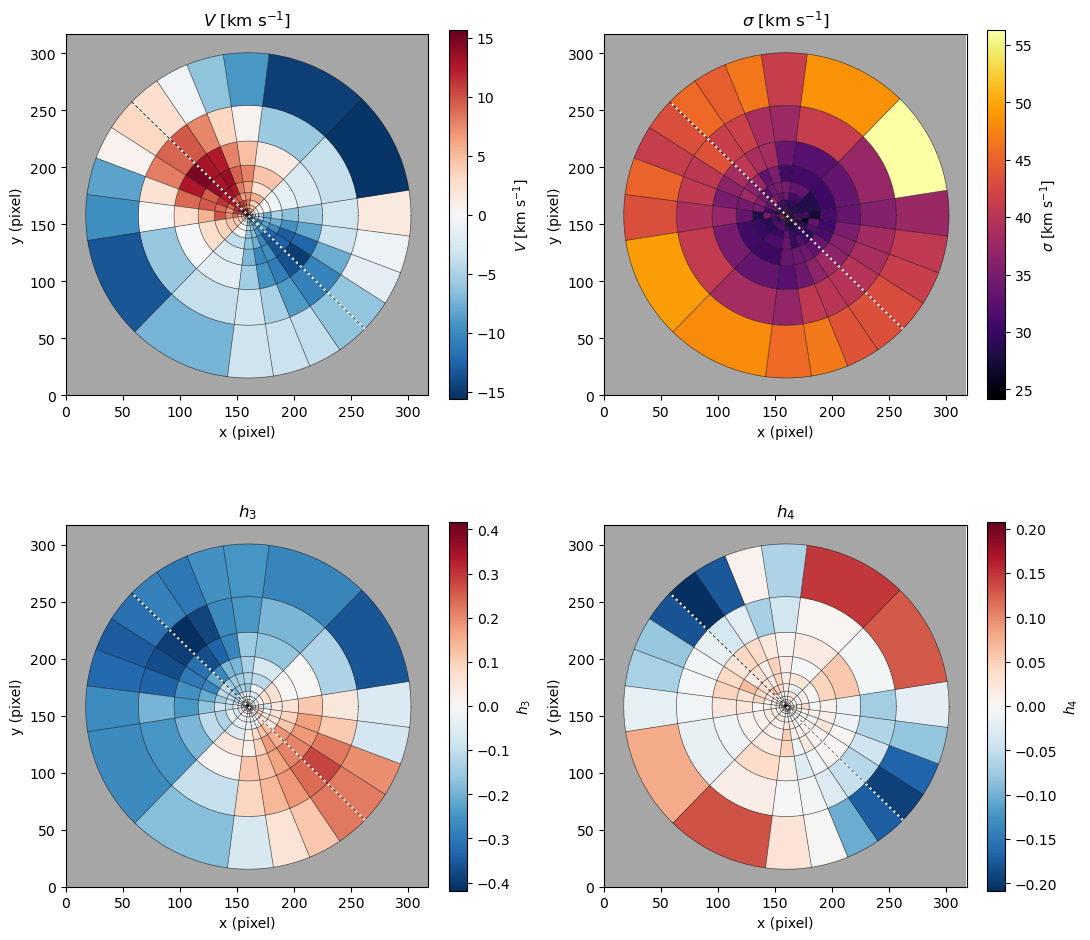

In [8]:
V = np.array([bin_data[b]["moments"]["vherm"] for b in bin_ids])
V -= np.nanmedian(V)  # remove the systemic velocity for plotting
SIGMA = np.array([bin_data[b]["moments"]["sherm"] for b in bin_ids])
H3 = np.array([bin_data[b]["moments"]["h3"] for b in bin_ids])
H3 -= np.nanmedian(H3)
H4 = np.array([bin_data[b]["moments"]["h4"] for b in bin_ids])

moment_names = ["V", "sigma", "h3", "h4"]
moment_labels = [r"$V$ [km s$^{-1}$]", r"$\sigma$ [km s$^{-1}$]", r"$h_3$", r"$h_4$"]
moment_vals = [V, SIGMA, H3, H4]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, name, label, vals in zip(axes.ravel(), moment_names, moment_labels, moment_vals):
    cmap = "inferno" if name == "sigma" else "RdBu_r"
    plot_bin_map(ax, bin_table, bins, dict(zip(bin_ids, vals)), center_pix=bins.center,
                 pa_deg=PA_DEG, pixel_scale=cube.pixel_scale, background=white_light,
                 cmap=cmap, colorbar_label=label)
    ax.set_xlim(0, nx); ax.set_ylim(0, ny)
    ax.set_title(label)
    ax.set_xlabel("x (pixel)"); ax.set_ylabel("y (pixel)")
plt.tight_layout(); plt.show()

## 7. Radial kinematic profiles -- V, sigma, h3, h4 along the major axis

The complementary view to the 2D maps above, and the one that actually
reads like a rotation curve: every bin's moment plotted against its own
*signed* distance along the kinematic major axis (positive on the receding
side, negative on the approaching side), restricted to a wedge of bins
close to that axis so the plotted points aren't smeared out across the
minor-axis direction where the LOSVD is dominated by dispersion, not
rotation. This is the same construction this project's own head-to-head
pPXF comparison uses for its own axis-profile plot.

Because `assign_spaxels_to_bins` was called with `pa_deg=PA_DEG`, every
bin's own `theta_mid` is *already* measured relative to the major axis (its
own `theta=0`) -- so the signed distance along the axis and the
perpendicular distance away from it fall out directly as
`r_mid*cos(theta_mid)` and `r_mid*sin(theta_mid)`, no extra rotation
needed.

43 of 219 bins selected within 11.5 deg of the major axis


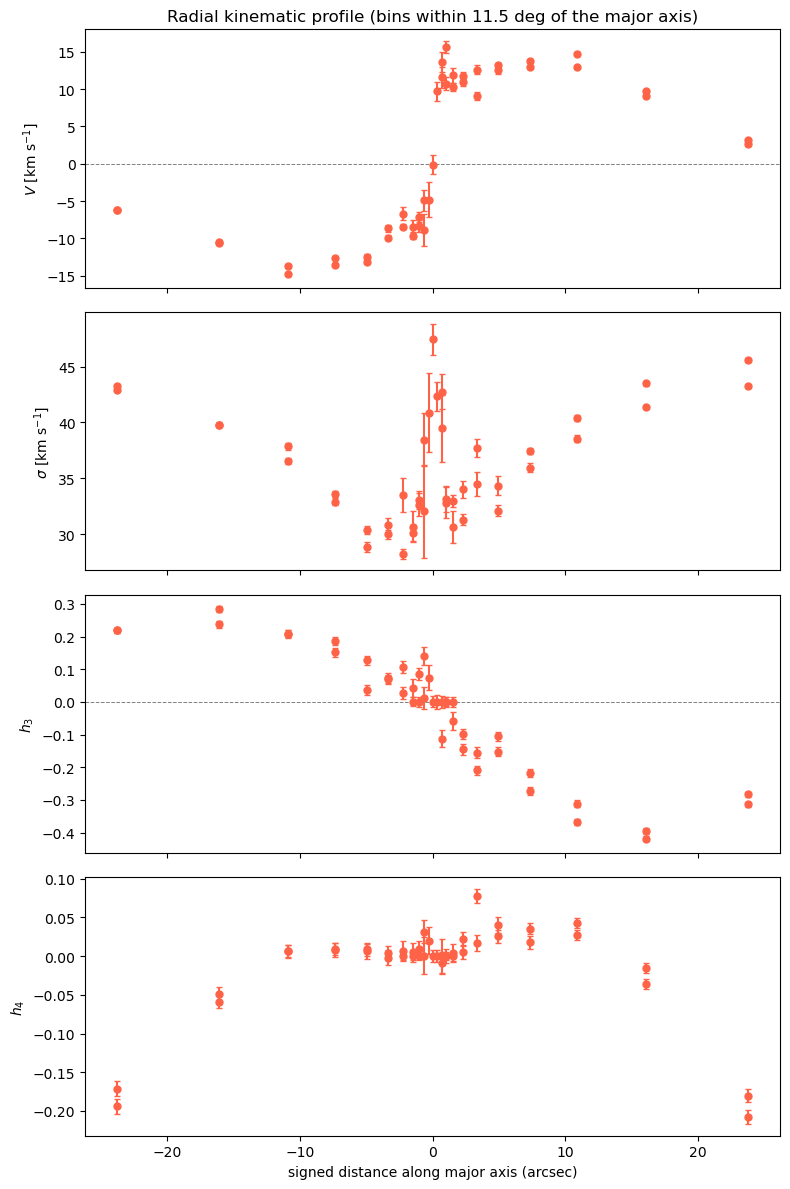

In [9]:
AXIS_HALF_WIDTH_DEG = 11.5  # angular wedge half-width around the major axis

r_signed = np.full(n_bins, 0.0)
d_perp = np.full(n_bins, 0.0)
is_center = np.zeros(n_bins, dtype=bool)
for i, bid in enumerate(bin_ids):
    bd = bin_data[bid]
    if bd["theta_mid"] is None:
        is_center[i] = True
        continue
    r_signed[i] = bd["r_mid"] * np.cos(bd["theta_mid"])
    d_perp[i] = bd["r_mid"] * np.sin(bd["theta_mid"])

# fold across the +/- axis direction (theta_mid near 0 or near pi are both "on axis")
phi_folded = np.minimum(np.abs(d_perp / np.maximum(np.array([bin_data[b]["r_mid"] for b in bin_ids]), 1e-6)),
                         1.0)
angle_from_axis_deg = np.degrees(np.arcsin(phi_folded))
axis_mask = (angle_from_axis_deg <= AXIS_HALF_WIDTH_DEG) | is_center

print(f"{axis_mask.sum()} of {n_bins} bins selected within {AXIS_HALF_WIDTH_DEG} deg of the major axis")

# y_limits = [(-18,18), (20, 80), (-0.4, 0.25), (-0.4, 0.4)]

fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)
for ax, name, label, vals in zip(axes, moment_names, moment_labels, moment_vals):
    errs = np.array([bin_data[b].get(f"{'vherm' if name=='V' else 'sherm' if name=='sigma' else 'h3' if name=='h3' else 'h4'}_std", 0.0)
                      for b in bin_ids])
    m = axis_mask
    order = np.argsort(r_signed[m])
    ax.errorbar(r_signed[m][order], vals[m][order], yerr=errs[m][order],
                fmt="o", color="tomato", ms=5, capsize=2)
    if name == "V" or name == "h3":
        ax.axhline(0.0, color="gray", lw=0.7, ls="--")
    # ax.set_ylim(y_limits[moment_names.index(name)])
    ax.set_ylabel(label)
axes[-1].set_xlabel('signed distance along major axis (arcsec)')
axes[0].set_title(f"Radial kinematic profile (bins within {AXIS_HALF_WIDTH_DEG} deg of the major axis)")
plt.tight_layout(); plt.show()

## Conclusion

**What this notebook did.** Combined every piece this notebook sequence
built and validated separately -- a calibrated template subset, PA-aware
spatial binning, sky/emission masking, correlated-noise whitening,
robust-scaled cleaning, and parallel Laplace uncertainty -- into a single,
real, full-galaxy analysis: moment maps and a radial kinematic profile
built directly from real MUSE data at production scale.

**Key takeaways:**

- Every earlier notebook's own validated choice shows up here as a
  concrete default: the calibrated template subset (04), the measured
  `rho` (05), Laplace as the primary uncertainty engine with bootstrap as
  a cross-check (02), robust-scaled cleaning tuned for this target's own
  elevated `chi2_red`.
- Failed or poorly-constrained bins degrade to `NaN` and render as plain
  grey on the moment maps, rather than crashing the whole run or silently
  reporting a meaningless number.
- **Real-data `chi2_red` runs well above 1 on this target even after
  correlated-noise whitening and cleaning** -- a real, only partially
  understood residual on top of everything this notebook applies. Treat
  the maps and profiles above as a demonstration of the full pipeline
  working end-to-end at real scale, not a publication-ready NGC 5102
  measurement.
- Uncertainty here is Laplace's own raw, uncorrected estimate, with no
  regularization-bias correction applied -- coverage is a real,
  substantial improvement over bootstrap but still below its nominal
  target, especially at low sigma.
- No continuum-cofitting in this notebook (`laplace_losvd_uncertainty`
  doesn't support it yet), and no per-bin `rho` re-measurement (`rho` is
  carried from a single reference aperture) -- both real, scoped
  simplifications, not oversights.

**This is the end of the notebook sequence for MUSE/E-MILES data.**
`06_other_instruments.ipynb` covers adapting this same pipeline to a
different instrument (HST/STIS) if that's what you need next. If you're
analyzing your own MUSE target, the natural path is: `04_template_calibration.ipynb`
to condition a template subset for it, `05_noise_correlation.ipynb` to
measure its own `rho`, then this notebook with `RMAX_ARCSEC`/`PA_DEG` set
to your target's own values.